# Exam Project 1: Customer Segmentation & Communication Strategy — Marketing Campaign

**Course:** AI for Communication and Marketing — B.Sc. in Artificial Intelligence

**Dataset:** Marketing Campaign Dataset (Kaggle)

**Goal:** Segment customers using RFM heuristics and K-Means clustering to drive a data-driven communication strategy

## Setup & Imports

In [1]:
# ── Imports ──
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import datetime
import warnings
warnings.filterwarnings('ignore')

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, calinski_harabasz_score

---
## Task A — Data Audit & Quality

In this section, it will be performed a comprehensive Data Audit to ensure the integrity of the dataset. 
The process includes:

1. **Handling Duplicates and Missing Values**: Identifying and cleaning incomplete records.

2. **Type Consistency**: Ensuring dates and categorical variables are correctly formatted for analysis.

3. **Outlier Detection**: Removing extreme values that could bias statistical models like K-Means.

### A.0 — Loading the Dataset

In [2]:
# Load the dataset
df = pd.read_csv('marketing_campaign.csv', sep=';')

# Initial inspection
display(df.head())
display(df.info())

,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
0,5524,1957,Graduation,Single,58138.0,0,0,2012-09-04,58,635,...,10,4,7,0,0,0,0,0,0,1
1,2174,1954,Graduation,Single,46344.0,1,1,2014-03-08,38,11,...,1,2,5,0,0,0,0,0,0,0
2,4141,1965,Graduation,Together,71613.0,0,0,2013-08-21,26,426,...,2,10,4,0,0,0,0,0,0,0
3,6182,1984,Graduation,Together,26646.0,1,0,2014-02-10,26,11,...,0,4,6,0,0,0,0,0,0,0
4,5324,1981,PhD,Married,58293.0,1,0,2014-01-19,94,173,...,3,6,5,0,0,0,0,0,0,0


<class 'pandas.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 27 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   str    
 3   Marital_Status       2240 non-null   str    
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   str    
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   int64  
 16 

None

### A.1 — Dataset Audit (Descriptive Statistics)

This step involves understanding the 'shape' of the data through the analysis of descriptive statistics for numerical variables and frequency distributions for categorical ones.

In [3]:
# Numerical Variables Descriptive Statistics
display(df.describe())

# Categorical Variables Frequency Distributions
display(df.describe(include='O'))

print("\n--- Education Frequency Distribution ---")
print(df['Education'].value_counts())
print("\n--- Marital Status Frequency Distribution ---")
print(df['Marital_Status'].value_counts())

,ID,Year_Birth,Income,Kidhome,Teenhome,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,...,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Response
count,2240.000000,2240.000000,2216.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,...,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000,2240.000000
mean,5592.159821,1968.805804,52247.251354,0.444196,0.506250,49.109375,303.935714,26.302232,166.950000,37.525446,...,2.662054,5.790179,5.316518,0.072768,0.074554,0.072768,0.064286,0.013393,0.009375,0.149107
std,3246.662198,11.984069,25173.076661,0.538398,0.544538,28.962453,336.597393,39.773434,225.715373,54.628979,...,2.923101,3.250958,2.426645,0.259813,0.262728,0.259813,0.245316,0.114976,0.096391,0.356274
min,0.000000,1893.000000,1730.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2828.250000,1959.000000,35303.000000,0.000000,0.000000,24.000000,23.750000,1.000000,16.000000,3.000000,...,0.000000,3.000000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
50%,5458.500000,1970.000000,51381.500000,0.000000,0.000000,49.000000,173.500000,8.000000,67.000000,12.000000,...,2.000000,5.000000,6.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
75%,8427.750000,1977.000000,68522.000000,1.000000,1.000000,74.000000,504.250000,33.000000,232.000000,50.000000,...,4.000000,8.000000,7.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
max,11191.000000,1996.000000,666666.000000,2.000000,2.000000,99.000000,1493.000000,199.000000,1725.000000,259.000000,...,28.000000,13.000000,20.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


,Education,Marital_Status,Dt_Customer
count,2240,2240,2240
unique,5,8,663
top,Graduation,Married,2012-08-31
freq,1127,864,12



--- Education Frequency Distribution ---
Education
Graduation    1127
PhD            486
Master         370
2n Cycle       203
Basic           54
Name: count, dtype: int64

--- Marital Status Frequency Distribution ---
Marital_Status
Married     864
Together    580
Single      480
Divorced    232
Widow        77
Alone         3
Absurd        2
YOLO          2
Name: count, dtype: int64


### A.2 — Data Quality (The Three Pillars)

Here, Duplicates, Missing Values and Outliers will be handled to ensure the data is properly vetted.

**1. Duplicates**

Check for and remove any exact duplicate rows.

**2. Missing Values**

Identification of columns with missing data and consequent application of logical imputation strategies to preserve the dataset.

In [4]:
# 1. Duplicates
print("Number of duplicate rows:", df.duplicated().sum())
df.drop_duplicates(inplace=True)

# 2. Missing Values
print("\n--- Missing Values ---")
missing_values = df.isnull().sum()
print(missing_values[missing_values > 0])

# Fix Data Types before proceeding
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%Y-%m-%d')

# Handle Missing Values via Imputation
# Imputing 'Income' with the median Income of the specific Education group the customer belongs to
# This provides a more realistic estimation of their wealth
df['Income'] = df.groupby('Education')['Income'].transform(lambda x: x.fillna(x.median()))

Number of duplicate rows: 0

--- Missing Values ---
Income    24
dtype: int64


**3. Categorical Sparsity (Marital Status & Education)**

To reduce dimensionality and noise for future clustering/machine learning steps, I'll here consolidate marginal and illogical marital statuses (like 'YOLO', 'Absurd', 'Alone') and educational levels (like 'Basic', '2n Cycle') into macro-categories based on household economic logic (`Single` vs `In Couple`).

In [5]:
# Consolidate sparse categorical variables into Macro Categories
macro_categories = {
    'Together': 'In Couple',
    'Married': 'In Couple',
    'Divorced': 'Single',
    'Widow': 'Single',
    'Alone': 'Single',
    'Absurd': 'Single',
    'YOLO': 'Single',
    'Single': 'Single'
}
df['Marital_Status'] = df['Marital_Status'].replace(macro_categories)

print("\n--- Consolidated Marital Status ---")
print(df['Marital_Status'].value_counts())


# Consolidate Education levels into 3 Macro Categories
education_macros = {
    'Basic': 'Undergraduate',
    'Graduation': 'Graduation',
    '2n Cycle': 'Postgraduate',
    'Master': 'Postgraduate',
    'PhD': 'Postgraduate'
}
df['Education'] = df['Education'].replace(education_macros)

print("\n--- Consolidated Education ---")
print(df['Education'].value_counts())


--- Consolidated Marital Status ---
Marital_Status
In Couple    1444
Single        796
Name: count, dtype: int64

--- Consolidated Education ---
Education
Graduation       1127
Postgraduate     1059
Undergraduate      54
Name: count, dtype: int64


In [6]:
# Converting categorical text columns into 'category' type to improve memory efficiency and ensure proper handling during analysis
df['Education'] = df['Education'].astype('category')
df['Marital_Status'] = df['Marital_Status'].astype('category')

# Displaying data types to confirm the change
print("Updated Data Types:")
print(df[['Education', 'Marital_Status']].dtypes)

Updated Data Types:
Education         category
Marital_Status    category
dtype: object


**4. Outliers**

Usage of visualizations to detect outliers in `Year_Birth` and `Income`, followed by aggressive removal actions as they disproportionately influence statistical measures.

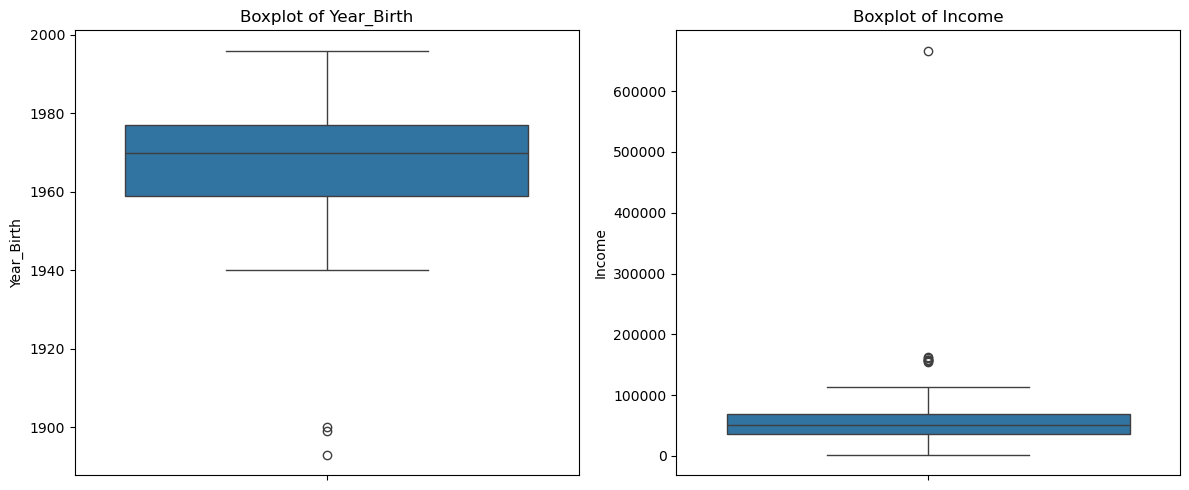

Oldest birth years:
 239     1893
339     1899
192     1900
1950    1940
424     1941
Name: Year_Birth, dtype: int64

Count of people for the oldest birth years:
 Year_Birth
1893    1
1899    1
1900    1
1940    1
1941    1
Name: count, dtype: int64

Highest incomes:
 2233    666666.0
617     162397.0
687     160803.0
1300    157733.0
164     157243.0
Name: Income, dtype: float64

Count of people for the highest incomes:
 Income
666666.0    1
162397.0    1
160803.0    1
157733.0    1
157243.0    1
Name: count, dtype: int64


In [7]:
# Visualizing outliers for key continuous variables
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df['Year_Birth'])
plt.title('Boxplot of Year_Birth')
plt.subplot(1, 2, 2)
sns.boxplot(y=df['Income'])
plt.title('Boxplot of Income')
plt.tight_layout()
plt.show()

# Look at specific statistics to identify the cutoffs
print("Oldest birth years:\n", df['Year_Birth'].sort_values().head())
print("\nCount of people for the oldest birth years:\n", df['Year_Birth'].value_counts().sort_index().head())
print("\nHighest incomes:\n", df['Income'].sort_values(ascending=False).head())
print("\nCount of people for the highest incomes:\n", df['Income'].value_counts().sort_index(ascending=False).head())


Shape after treating outliers: (2236, 27)


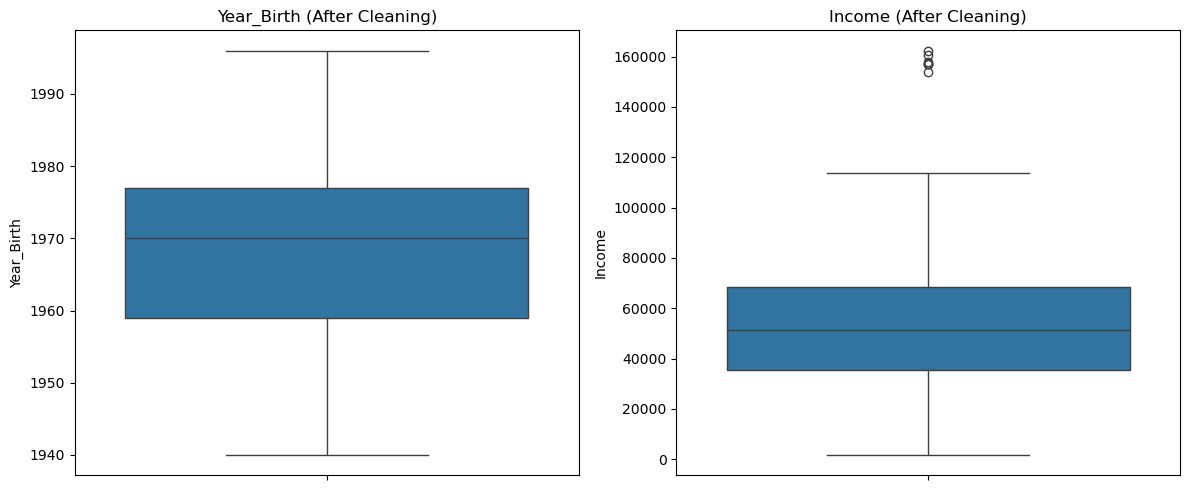

In [8]:
# Action: Removal
# Remove obvious age outliers (e.g., born before 1920)
df = df[df['Year_Birth'] >= 1920]

# Remove extreme high income outliers (using a reasonable upper threshold 200,000)
df = df[df['Income'] <= 200000]

print("\nShape after treating outliers:", df.shape)

# Visualize the data AFTER outlier removal to confirm the cleaning effect
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.boxplot(y=df['Year_Birth'])
plt.title('Year_Birth (After Cleaning)')
plt.subplot(1, 2, 2)
sns.boxplot(y=df['Income'])
plt.title('Income (After Cleaning)')
plt.tight_layout()
plt.show()

### Documentation of the Cleaning Process

**Summary of Choices Made:**

- **Imputation (`Income`):** I chose to **impute missing values with the median** instead of the mean. This is due to the fact that Income distributions are often right-skewed and, consequently, imputing the mean would artificially inflate the substituted values due to extreme high-income outliers.

- **Categorical Grouping (`Marital_Status`):** I grouped sparse and irrational categories ('YOLO', 'Absurd', 'Alone') into two actionable financial macro-segments: `Single` and `In Couple`. This solves data sparsity and prevents dummy-variable explosions for future modeling.

- **Categorical Grouping (`Education`):** I grouped marginal and redundant educational labels ('Basic', '2n Cycle') alongside 'Master' and 'PhD' into 3 robust macro-categories: `Undergraduate`, `Graduation`, and `Postgraduate`. This eliminates statistical noise from under-represented classes and standardizes educational levels based on generalized income capabilities.

- **Transformation (`Dt_Customer`):** I transformed the enrollment date from a string (`object`) to a `datetime` object to properly use it for time-based calculations.

- **Type Conversion (`Education` & `Marital_Status`):** After consolidating both columns into their final macro-categories, I explicitly transformed them into Pandas `'category'` dtype. This optimizes memory usage and signals to downstream models that these are nominal/categorical variables, not free-form strings.

- **Dropping Data Points (Outliers):**
  - **Age Outliers:** I chose to **drop** instances with birth years before 1920 (e.g., 1893) since they are likely data entry errors or placeholders that would distort demographic analysis.
  - **Income Outliers:** I chose to **drop** instances with incomes > 200,000. As clearly visible in the previous boxplot, the values above this threshold appear completely isolated from the main distribution and are not representative of the mass. Extremely high incomes heavily distort mathematical averages and disrupt distance-based clustering algorithms (like K-Means). Because the number of these records is negligible, strategic removal is safer than capping.

---
## Task B — Exploratory Data Analysis (EDA)

### B.1 — Defining Key Performance Indicators (KPIs)

Translating raw data into measurable marketing outcomes.

In [9]:
# KPI 1: Total Spending (Monetary)
# The monetary value contributed by each customer across all product categories
df['Total_Spending'] = df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] + df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds']

# KPI 2: Frequency
# The number of orders placed (overall channels combined, excluding deals to capture organic purchase frequency)
df['Total_Purchases'] = df['NumWebPurchases'] + df['NumCatalogPurchases'] + df['NumStorePurchases']

# KPI 3: Retention Rate Matrix
# Considering active users those who made a purchase in the last 60 days
df['Is_Active'] = (df['Recency'] <= 60).astype(int)

print("--- KPI Averages ---")
print(f"Average Customer Spending: ${df['Total_Spending'].mean():.2f}")
print(f"Average Purchase Frequency: {df['Total_Purchases'].mean():.2f} orders")
print(f"Retention Rate (Active within 60 days): {df['Is_Active'].mean() * 100:.2f}%")

display(df[['ID', 'Total_Spending', 'Total_Purchases', 'Is_Active']].head())

--- KPI Averages ---
Average Customer Spending: $605.99
Average Purchase Frequency: 12.55 orders
Retention Rate (Active within 60 days): 61.49%


,ID,Total_Spending,Total_Purchases,Is_Active
0,5524,1617,22,1
1,2174,27,4,1
2,4141,776,20,1
3,6182,53,6,1
4,5324,422,14,0


### B.2 — Feature Engineering: Creating Advanced Variables

To extract a stronger signal for subsequent modeling, here fragmented variables will be combined into powerful unified concepts:

- **`Total_Children`**: A numeric tracker combining all minors.

- **`Total_Promos_Accepted`**: The total historical campaign responsiveness (scale 0-6).

- **`Has_Accepted_Any_Promo`**: A swift binary indicator tracking absolute campaign success.

In [10]:
# 1. Total Household Minors
df['Total_Children'] = df['Kidhome'] + df['Teenhome']

# 2. Total Historical Campaign Acceptance
campaign_cols = ['AcceptedCmp1', 'AcceptedCmp2', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'Response']
df['Total_Promos_Accepted'] = df[campaign_cols].sum(axis=1)

# 3. Binary Indicator for Any Acceptance
df['Has_Accepted_Any_Promo'] = (df['Total_Promos_Accepted'] > 0).astype(int)

display(df[['ID', 'Total_Children', 'Total_Promos_Accepted', 'Has_Accepted_Any_Promo']].head())

,ID,Total_Children,Total_Promos_Accepted,Has_Accepted_Any_Promo
0,5524,0,1,1
1,2174,2,0,0
2,4141,0,0,0
3,6182,1,0,0
4,5324,1,0,0


### B.3 — Correlation Details: Socio-Demographics vs Total Spending

Here I investigate how features like `Income`, `Year_Birth` (translated to `Age`), and family dynamics (`Kidhome`, `Teenhome`) correlate with `Total_Spending`.

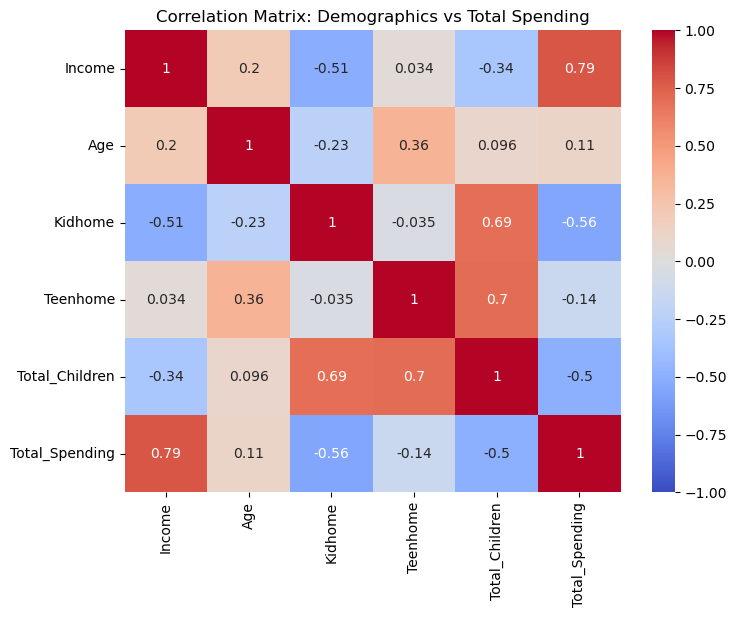

In [11]:
# Create an Age column for better demographic analysis
current_year = datetime.datetime.now().year
df['Age'] = current_year - df['Year_Birth']

# Select socio-demographic features and total spending
demographic_features = ['Income', 'Age', 'Kidhome', 'Teenhome', 'Total_Children', 'Total_Spending']

# Calculate correlation matrix
corr_matrix = df[demographic_features].corr()

# Visualize the correlation matrix
plt.figure(figsize=(8, 6))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Correlation Matrix: Demographics vs Total Spending')
plt.show()

**Observations:**
- **Income** has a strongly positive correlation with `Total_Spending`. Higher income translates directly to more spending.
- **Kidhome** has a negative correlation with `Total_Spending`, meaning customers with small children tend to spend less overall.
- **Total_Children** acts as a unified negative correlator with `Total_Spending`; larger families intuitively scale back on luxury/hedonic marketing offerings compared to childless households.
- **Age** typically shows a weak-to-moderate positive correlation, indicating older customers might have slightly more disposable income.

### B.4 — Purchase Distribution Across Channels

Let's now see which channels are driving the most transactions.

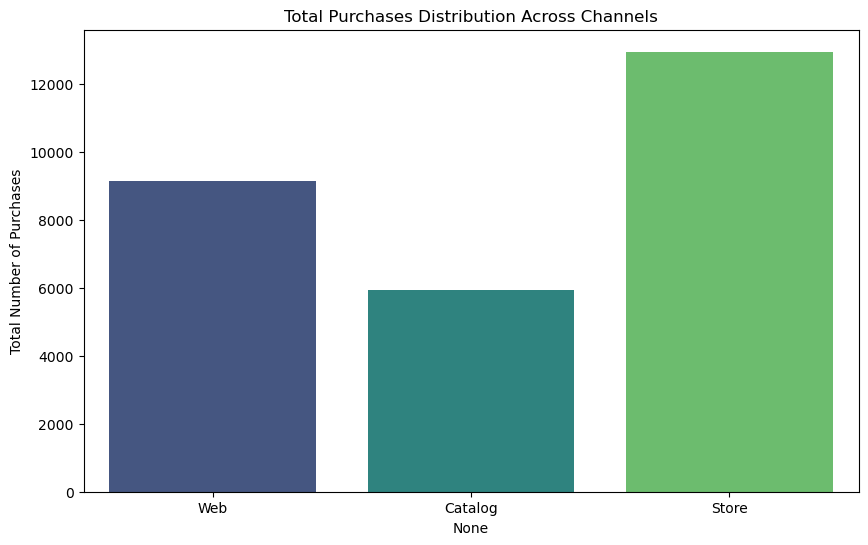

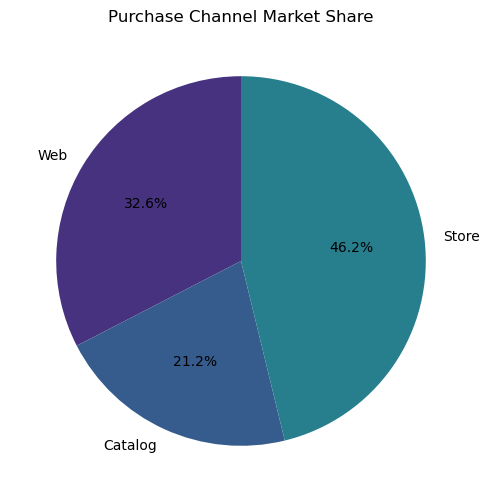

In [12]:
# Aggregate total purchases per channel
channels = ['NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases']
channel_totals = df[channels].sum()

plt.figure(figsize=(10, 6))
sns.barplot(x=channel_totals.index, y=channel_totals.values, palette='viridis')
plt.title('Total Purchases Distribution Across Channels')
plt.ylabel('Total Number of Purchases')
plt.xticks(ticks=[0, 1, 2], labels=['Web', 'Catalog', 'Store'])
plt.show()

# We can also plot a pie chart for better percentage perspective
plt.figure(figsize=(6, 6))
plt.pie(channel_totals, labels=['Web', 'Catalog', 'Store'], autopct='%1.1f%%', startangle=90, colors=sns.color_palette('viridis'))
plt.title('Purchase Channel Market Share')
plt.show()

**Observations:**
The visual distributions highlight the most utilized platform. The Catalog represents the smallest physical footprint for order volumes.

### B.5 — Communication Insight: Hidden Trend for a Promotional Campaign

By cross-analyzing different segments, I will try to uncover a hidden niche. Let's look at the relationship between having teenagers (`Teenhome`), kids (`Kidhome`) and specific product categories (like `MntWines` vs `NumDealsPurchases`).

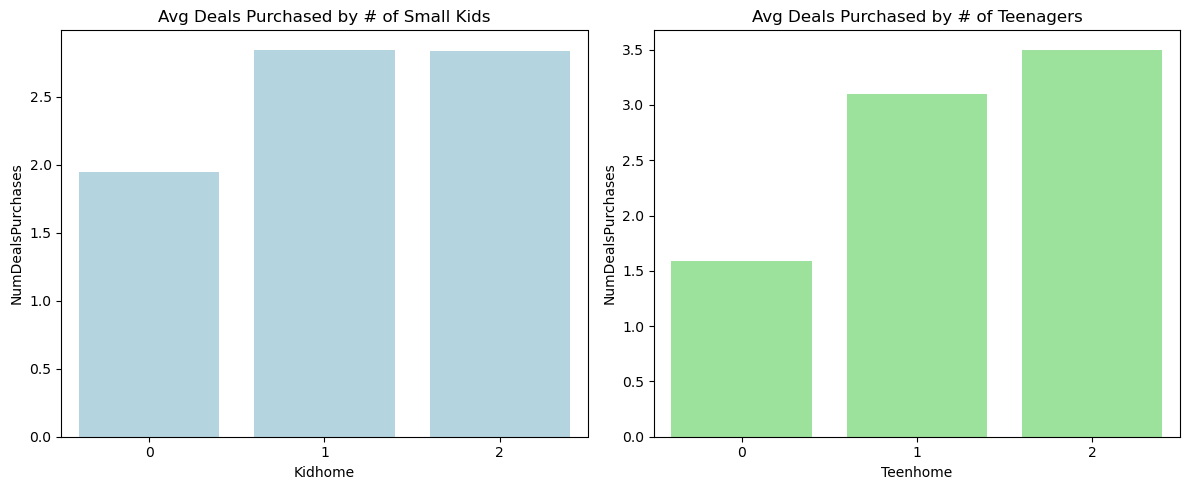

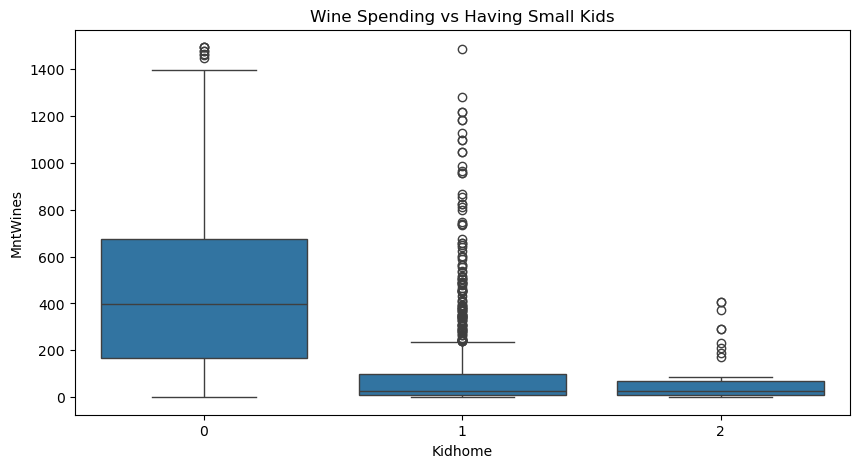

In [13]:
# Let's explore Deals vs Family structure
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.barplot(x='Kidhome', y='NumDealsPurchases', data=df, errorbar=None, color='lightblue')
plt.title('Avg Deals Purchased by # of Small Kids')

plt.subplot(1, 2, 2)
sns.barplot(x='Teenhome', y='NumDealsPurchases', data=df, errorbar=None, color='lightgreen')
plt.title('Avg Deals Purchased by # of Teenagers')

plt.tight_layout()
plt.show()

# Let's check Spending on Wine vs Family Structure
plt.figure(figsize=(10, 5))
sns.boxplot(x='Kidhome', y='MntWines', data=df)
plt.title('Wine Spending vs Having Small Kids')
plt.show()

**Actionable Insight for Targeted Campaign:**
- **Hidden Trend:** Families with teenagers (`Teenhome` ≥ 1) generally display a high propensity to use discounts/deals (`NumDealsPurchases`), whereas families with small children (`Kidhome` ≥ 1) cut down heavily on luxury/indulgence items like Wine.
- **The Campaign ("Smart Family Indulgence"):** We can target households with teenagers by offering bundled deals. Since these households actively seek out discounts, a targeted email or web campaign featuring bundled discounts on high-margin items (like mid-tier wines or bulk meat products) could drive massive engagement. They are price-sensitive but not entirely cutting out products like parents with toddlers, so sending them targeted deals maximizes conversion.

### B.6 — Additional Insight: Campaign Responders & Catalog Affinity

Let's analyze which purchasing channels are preferred by customers who actively accept our marketing campaigns.

,Total_Promos_Accepted
NumCatalogPurchases,0.351304
NumWebPurchases,0.205057
NumStorePurchases,0.172721


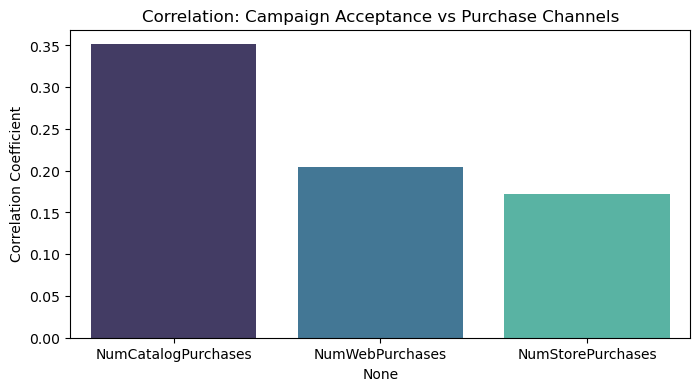

In [14]:
# Correlation between Total Promos Accepted and purchase channels
promo_channels = ['Total_Promos_Accepted', 'NumCatalogPurchases', 'NumWebPurchases', 'NumStorePurchases']
corrs_promo = df[promo_channels].corr()[['Total_Promos_Accepted']].loc[['NumCatalogPurchases', 'NumWebPurchases', 'NumStorePurchases']].sort_values(by='Total_Promos_Accepted', ascending=False)
display(corrs_promo)

plt.figure(figsize=(8, 4))
sns.barplot(x=corrs_promo.index, y=corrs_promo['Total_Promos_Accepted'], palette='mako')
plt.title('Correlation: Campaign Acceptance vs Purchase Channels')
plt.ylabel('Correlation Coefficient')
plt.show()

**Actionable Insight for Targeted Campaign:**
- Customers who accept promotions are primarily catalog buyers (strongest correlation at ~0.35), whereas web and store purchases show much weaker correlations. This suggests that future promotional campaigns or premium discounting should be aggressively targeted via the Catalog channel rather than digital ads.

### B.7 — Additional Insight: The 'Window Shopper' Effect 

Let's verify if high website traffic (`NumWebVisitsMonth`) correlates with high purchases online or offline (the ROPO effect: Research Online, Purchase Offline).

,NumWebVisitsMonth
NumWebPurchases,-0.056204
NumStorePurchases,-0.429857


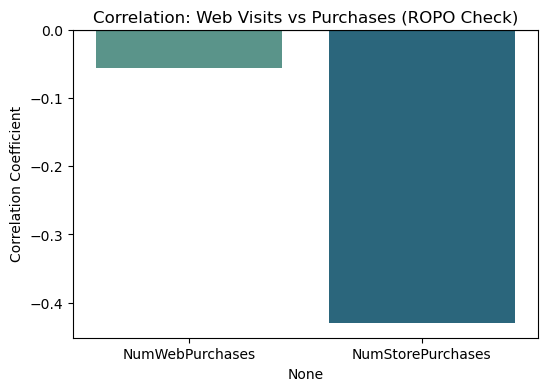

In [15]:
# ROPO Effect Check
ropo_cols = ['NumWebVisitsMonth', 'NumWebPurchases', 'NumStorePurchases']
corrs_ropo = df[ropo_cols].corr()[['NumWebVisitsMonth']].loc[['NumWebPurchases', 'NumStorePurchases']]
display(corrs_ropo)

plt.figure(figsize=(6, 4))
sns.barplot(x=corrs_ropo.index, y=corrs_ropo['NumWebVisitsMonth'], palette='crest')
plt.title('Correlation: Web Visits vs Purchases (ROPO Check)')
plt.ylabel('Correlation Coefficient')
plt.axhline(0, color='black', linewidth=0.8)
plt.show()

**Actionable Insight for Marketing Strategy:**
- Counterintuitively, website visits are negatively correlated with both Web (-0.05) and Store (-0.42) purchases. This implies massive but non-converting traffic ('Window Shoppers'). To address this, the marketing team could introduce scarcity tactics on the website (e.g., 24-hour Flash Sales) to incentivize quick conversion before visitors leave.

---
## Task C — RFM Calculation & Heuristic Segmentation

### Methodology Justification: The "Data-Driven Threshold" Approach

While standard RFM implementations often rely on a **mechanical percentile split** (e.g., dividing the customer base into rigid quintiles and calculating a weighted aggregate score), this project implements an **advanced, data-driven threshold methodology** inspired by real-world CRM business cases (e.g., the *LSD Industry* model seen in class).

This methodological shift was necessary for three core reasons based on our Exploratory Data Analysis:

1. **Handling Skewed Distributions & The "One-Shooter" Anomaly:** Our dataset features a massive proportion of customers who made exactly one purchase. By using empirical thresholds (quartiles), I'll naturally group and isolate the "One-Purchase" behavior.

2. **Avoiding "Aggregated Score" Distortions:** Combining R, F, and M into a single weighted score can be highly misleading. A customer who bought once two years ago but spent $10,000 could mathematically achieve the same total score as a consistent weekly buyer who spends $10. By replacing the weighted sum with a **Categorical Matrix Intersection (R×F)**, I can evaluate behavioral loyalty first, completely separating true regulars from dormant high-spenders.

3. **Hierarchical Use of Variables:** I'll use Recency and Frequency to define the core behavioral engagement (Regulars, One-Purchase, Decreasing). Then, **monetary** is  applied hierarchically as a "value magnifier" (using tertiles) *only* on the Regulars to establish profitability tiers (Gold, Silver, Bronze).

This approach prevents blurred segments and produces a highly actionable, 5-tier segmentation ready for direct marketing campaign deployment.

### C.1 — RFM Features Formatting

The foundational metrics have been already engineered during EDA. For the RFM model, I will isolate:

- **Recency (R):** Days since the last purchase (`Recency`).

- **Frequency (F):** Total number of organic purchases (`Total_Purchases`).

- **Monetary (M):** Total amount spent (`Total_Spending`). 

In [16]:
# Isolating RFM variables from our main dataframe
rfm_df = df[['ID', 'Recency', 'Total_Purchases', 'Total_Spending']].copy()
rfm_df.rename(columns={
    'Recency': 'Recency',
    'Total_Purchases': 'Frequency',
    'Total_Spending': 'Monetary'
}, inplace=True)

display(rfm_df.head())

,ID,Recency,Frequency,Monetary
0,5524,58,22,1617
1,2174,38,4,27
2,4141,26,20,776
3,6182,26,6,53
4,5324,94,14,422


### C.2 — Data-Driven Threshold Analysis (R & F)

Rather than applying uniform quintiles, I here derive thresholds **empirically from the data distribution** using quartiles for Recency and Frequency.

=== Recency Thresholds (days since last purchase) ===
  R1 (<=Q1) : <= 24 days  -> Very Recent
  R2 (Q1-Q2): 24-49 days  -> Recent
  R3 (Q2-Q3): 49-74 days  -> Moderate
  R4 (>Q3)  : > 74 days  -> Distant

=== Frequency Thresholds (total purchases) ===
  F1 (<=Q1) : <= 6 purchases  -> Low
  F2 (Q1-Q2): 6-12 purchases  -> Below Average
  F3 (Q2-Q3): 12-18 purchases  -> Above Average
  F4 (>Q3)  : > 18 purchases  -> High


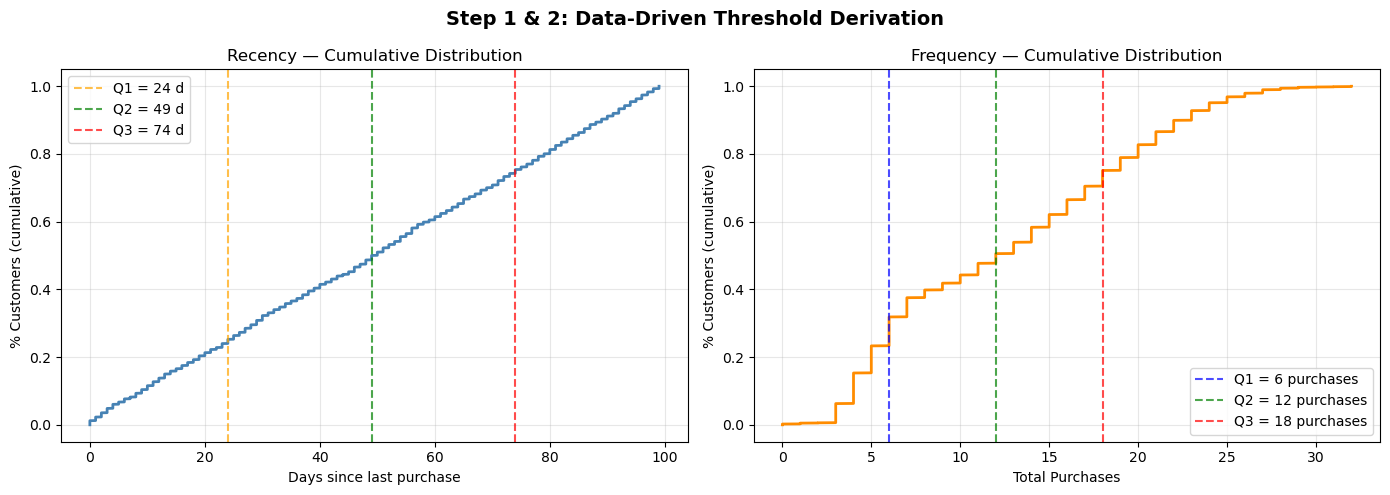

In [17]:
# ── Step 1 & 2: Compute Quartile Thresholds for Recency and Frequency ──

# Recency: lower = more recent = better
r_q1 = rfm_df['Recency'].quantile(0.25)
r_q2 = rfm_df['Recency'].quantile(0.50)
r_q3 = rfm_df['Recency'].quantile(0.75)

# Frequency: higher = more purchases = better
f_q1 = rfm_df['Frequency'].quantile(0.25)
f_q2 = rfm_df['Frequency'].quantile(0.50)
f_q3 = rfm_df['Frequency'].quantile(0.75)

print('=== Recency Thresholds (days since last purchase) ===')
print(f'  R1 (<=Q1) : <= {r_q1:.0f} days  -> Very Recent')
print(f'  R2 (Q1-Q2): {r_q1:.0f}-{r_q2:.0f} days  -> Recent')
print(f'  R3 (Q2-Q3): {r_q2:.0f}-{r_q3:.0f} days  -> Moderate')
print(f'  R4 (>Q3)  : > {r_q3:.0f} days  -> Distant')

print('\n=== Frequency Thresholds (total purchases) ===')
print(f'  F1 (<=Q1) : <= {f_q1:.0f} purchases  -> Low')
print(f'  F2 (Q1-Q2): {f_q1:.0f}-{f_q2:.0f} purchases  -> Below Average')
print(f'  F3 (Q2-Q3): {f_q2:.0f}-{f_q3:.0f} purchases  -> Above Average')
print(f'  F4 (>Q3)  : > {f_q3:.0f} purchases  -> High')

# ── Visualise Cumulative Distributions (CDF) ──
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Recency CDF
recency_sorted = rfm_df['Recency'].sort_values()
cdf_r = np.arange(1, len(recency_sorted) + 1) / len(recency_sorted)
axes[0].plot(recency_sorted, cdf_r, color='steelblue', linewidth=2)
for q, lbl, clr in [(r_q1, 'Q1', 'orange'), (r_q2, 'Q2', 'green'), (r_q3, 'Q3', 'red')]:
    axes[0].axvline(q, linestyle='--', color=clr, alpha=0.7, label=f'{lbl} = {q:.0f} d')
axes[0].set_title('Recency — Cumulative Distribution')
axes[0].set_xlabel('Days since last purchase')
axes[0].set_ylabel('% Customers (cumulative)')
axes[0].legend()
axes[0].grid(True, alpha=0.3)

# Frequency CDF
freq_sorted = rfm_df['Frequency'].sort_values()
cdf_f = np.arange(1, len(freq_sorted) + 1) / len(freq_sorted)
axes[1].plot(freq_sorted, cdf_f, color='darkorange', linewidth=2)
for q, lbl, clr in [(f_q1, 'Q1', 'blue'), (f_q2, 'Q2', 'green'), (f_q3, 'Q3', 'red')]:
    axes[1].axvline(q, linestyle='--', color=clr, alpha=0.7, label=f'{lbl} = {q:.0f} purchases')
axes[1].set_title('Frequency — Cumulative Distribution')
axes[1].set_xlabel('Total Purchases')
axes[1].set_ylabel('% Customers (cumulative)')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.suptitle('Step 1 & 2: Data-Driven Threshold Derivation', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### C.3 — R×F Intersection (3 Macro-Groups)

By intersecting Recency and Frequency **3 behavioural macro-groups** are obtained:

- **One-Purchase:** Customers with very low Frequency (F ≤ Q1). Regardless of recency, they barely engaged with the brand.

- **Decreasing:** Formerly frequent buyers (F ≥ Q2) who have gone silent (R > Q3). High churn risk.

- **Regulars:** All remaining customers — consistent and balanced R×F combinations.

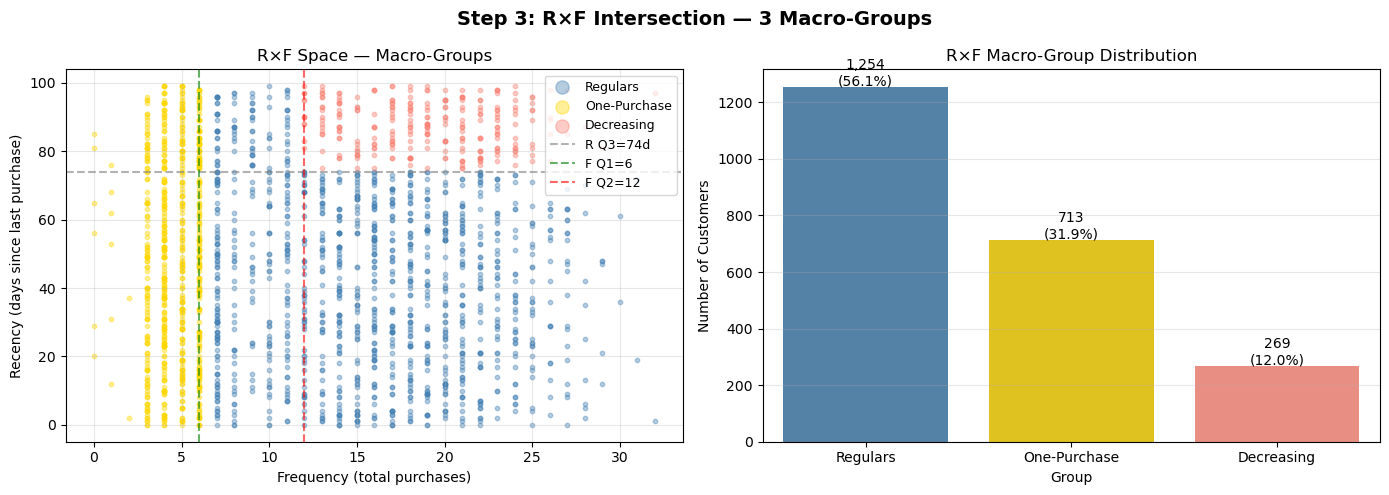


Group Profiles (mean values):


,Recency,Frequency
RF_Group,,
Decreasing,87.6,18.9
One-Purchase,48.9,4.5
Regulars,41.0,15.7


In [18]:
# ── Step 3: R×F Macro-Group Assignment ──
def assign_rf_group(row):
    r = row['Recency']
    f = row['Frequency']
    if f <= f_q1:
        return 'One-Purchase'
    elif r > r_q3 and f >= f_q2:
        return 'Decreasing'
    else:
        return 'Regulars'

rfm_df['RF_Group'] = rfm_df.apply(assign_rf_group, axis=1)

rf_counts = rfm_df['RF_Group'].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Scatter: Recency vs Frequency coloured by RF group
colors_map = {'Regulars': 'steelblue', 'One-Purchase': 'gold', 'Decreasing': 'salmon'}
for group, clr in colors_map.items():
    mask = rfm_df['RF_Group'] == group
    axes[0].scatter(rfm_df.loc[mask, 'Frequency'], rfm_df.loc[mask, 'Recency'],
                    color=clr, alpha=0.4, label=group, s=10)
axes[0].axhline(r_q3, linestyle='--', color='grey', alpha=0.6, label=f'R Q3={r_q3:.0f}d')
axes[0].axvline(f_q1, linestyle='--', color='green', alpha=0.6, label=f'F Q1={f_q1:.0f}')
axes[0].axvline(f_q2, linestyle='--', color='red', alpha=0.6, label=f'F Q2={f_q2:.0f}')
axes[0].set_title('R×F Space — Macro-Groups')
axes[0].set_xlabel('Frequency (total purchases)')
axes[0].set_ylabel('Recency (days since last purchase)')
axes[0].legend(markerscale=3, fontsize=9)
axes[0].grid(True, alpha=0.3)

# Bar chart of group sizes
bar_colors = [colors_map[g] for g in rf_counts.index]
sns.barplot(x=rf_counts.index, y=rf_counts.values, palette=bar_colors, ax=axes[1])
for i, v in enumerate(rf_counts.values):
    axes[1].text(i, v + 5, f'{v:,}\n({v/len(rfm_df)*100:.1f}%)', ha='center', fontsize=10)
axes[1].set_title('R×F Macro-Group Distribution')
axes[1].set_xlabel('Group')
axes[1].set_ylabel('Number of Customers')
axes[1].grid(True, alpha=0.3, axis='y')

plt.suptitle('Step 3: R×F Intersection — 3 Macro-Groups', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nGroup Profiles (mean values):')
display(rfm_df.groupby('RF_Group')[['Recency', 'Frequency']].mean().round(1))

### C.4 — Monetary Threshold Analysis

For the monetary I arbitrarily choose to split it into **3 tiers using tertiles** (33rd and 67th percentiles):

- **Low Spending** (≤ 33rd pct)
- **Average Spending** (33rd–67th pct)
- **High Spending** (> 67th pct)

=== Monetary Thresholds (total spending $) ===
  Low Spending    : <= 115
  Average Spending: 115 - 832
  High Spending   : > 832


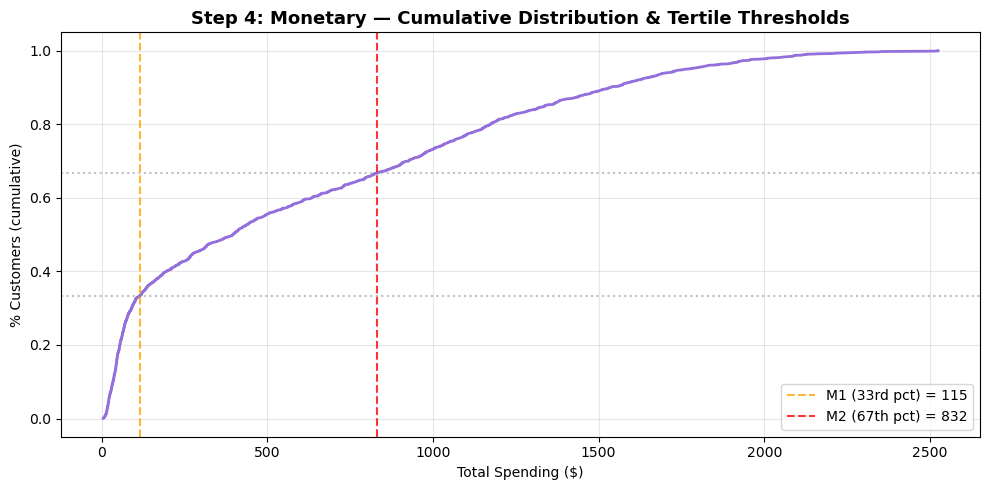


Monetary Group Distribution:
  Low: 746 (33.4%)
  High: 745 (33.3%)
  Average: 745 (33.3%)


In [19]:
# ── Step 4: Monetary Tertile Thresholds ──
m_q1 = rfm_df['Monetary'].quantile(1/3)
m_q2 = rfm_df['Monetary'].quantile(2/3)

print('=== Monetary Thresholds (total spending $) ===')
print(f'  Low Spending    : <= {m_q1:.0f}')
print(f'  Average Spending: {m_q1:.0f} - {m_q2:.0f}')
print(f'  High Spending   : > {m_q2:.0f}')

def assign_m_group(val):
    if val <= m_q1:
        return 'Low'
    elif val <= m_q2:
        return 'Average'
    else:
        return 'High'

rfm_df['M_Group'] = rfm_df['Monetary'].apply(assign_m_group)

# ── Visualise Monetary CDF with thresholds ──
plt.figure(figsize=(10, 5))
monetary_sorted = rfm_df['Monetary'].sort_values()
cdf_m = np.arange(1, len(monetary_sorted) + 1) / len(monetary_sorted)
plt.plot(monetary_sorted, cdf_m, color='mediumpurple', linewidth=2)
plt.axvline(m_q1, linestyle='--', color='orange', alpha=0.8, label=f'M1 (33rd pct) = {m_q1:.0f}')
plt.axvline(m_q2, linestyle='--', color='red', alpha=0.8, label=f'M2 (67th pct) = {m_q2:.0f}')
plt.axhline(1/3, linestyle=':', color='grey', alpha=0.5)
plt.axhline(2/3, linestyle=':', color='grey', alpha=0.5)
plt.title('Step 4: Monetary — Cumulative Distribution & Tertile Thresholds',
          fontsize=13, fontweight='bold')
plt.xlabel('Total Spending ($)')
plt.ylabel('% Customers (cumulative)')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print('\nMonetary Group Distribution:')
for group, count in rfm_df['M_Group'].value_counts().items():
    print(f'  {group}: {count:,} ({count/len(rfm_df)*100:.1f}%)')

### C.5 — Final Segments (R×F × Monetary)

By intersecting **RF_Group** and **M_Group**, **5 final actionable segments** are obtained:

| RF Group | Monetary | Final Segment |
|---|---|---|
| Regulars | High | **Gold** |
| Regulars | Average | **Silver** |
| Regulars | Low | **Bronze** |
| One-Purchase | Any | **One-Shooter** |
| Decreasing | Any | **Irregular** |

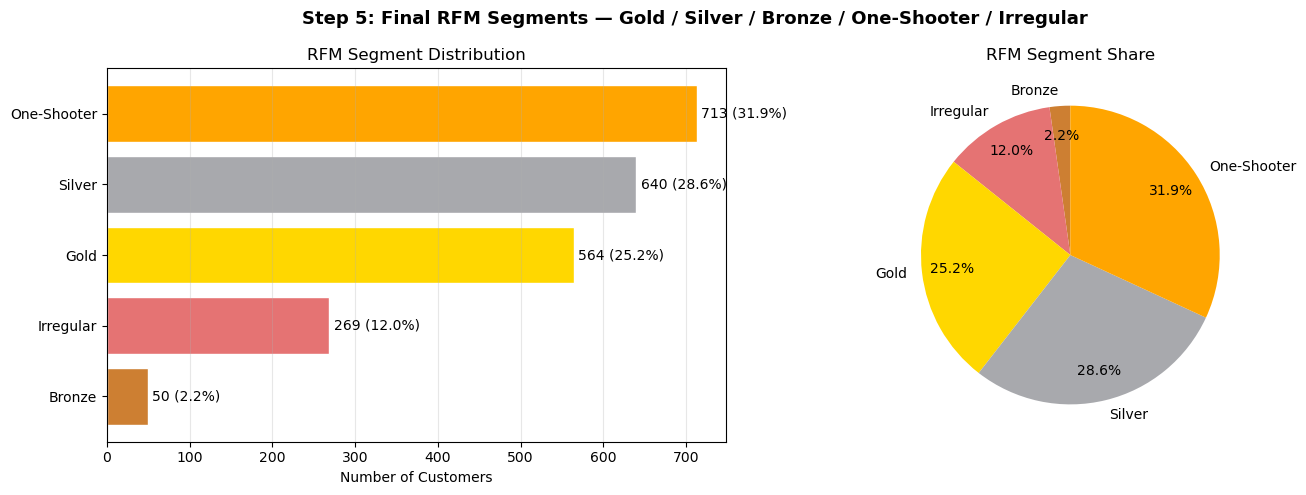


Segment Statistical Profiles:


,Recency,Frequency,Monetary
Segment,,,
Bronze,48.3,7.0,75.6
Gold,38.6,19.8,1345.9
Irregular,87.6,18.9,1107.2
One-Shooter,48.9,4.5,54.0
Silver,42.5,12.8,399.6


In [20]:
# ── Step 5: Final Segment Assignment ──
def assign_final_segment(row):
    rf = row['RF_Group']
    m  = row['M_Group']
    if rf == 'One-Purchase':
        return 'One-Shooter'
    elif rf == 'Decreasing':
        return 'Irregular'
    else:  # Regulars
        if m == 'High':
            return 'Gold'
        elif m == 'Average':
            return 'Silver'
        else:
            return 'Bronze'

rfm_df['Segment'] = rfm_df.apply(assign_final_segment, axis=1)

# ── Visualise Final Segments ──
seg_palette = {
    'Gold':        '#FFD700',
    'Silver':      '#A8A9AD',
    'Bronze':      '#CD7F32',
    'One-Shooter': '#FFA500',
    'Irregular':   '#E57373',
}
seg_counts = rfm_df['Segment'].value_counts().sort_values(ascending=True)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Horizontal bar
colors_bar = [seg_palette[s] for s in seg_counts.index]
axes[0].barh(seg_counts.index, seg_counts.values, color=colors_bar, edgecolor='white')
for i, (seg, val) in enumerate(zip(seg_counts.index, seg_counts.values)):
    axes[0].text(val + 5, i, f'{val:,} ({val/len(rfm_df)*100:.1f}%)', va='center', fontsize=10)
axes[0].set_title('RFM Segment Distribution')
axes[0].set_xlabel('Number of Customers')
axes[0].grid(True, alpha=0.3, axis='x')

# Pie chart
axes[1].pie(
    seg_counts.values,
    labels=seg_counts.index,
    colors=[seg_palette[s] for s in seg_counts.index],
    autopct='%1.1f%%',
    startangle=90,
    pctdistance=0.8
)
axes[1].set_title('RFM Segment Share')

plt.suptitle(
    'Step 5: Final RFM Segments — Gold / Silver / Bronze / One-Shooter / Irregular',
    fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

print('\nSegment Statistical Profiles:')
display(rfm_df.groupby('Segment')[['Recency', 'Frequency', 'Monetary']].mean().round(1))

### C.6 — Segment Marketing Strategy

Based on the final segmentation, each group receives a tailored marketing strategy:

| Segment | Strategic Goal | Marketing Actions |
|---|---|---|
| **Gold** | Gratification | Keep loyalty high; brand ambassador initiatives; exclusive rewards |
| **Silver** | Spending Increase | Encourage purchase of high-margin products; cross-selling |
| **Bronze** | Spending Increase | Targeted offers, upselling campaigns |
| **One-Shooter** | Frequency Increase | Pricing actions and incentives to drive a second purchase |
| **Irregular** | Churn Prevention | Ad-hoc reactivation activities to intercept behavioral decline |

---
## Task D — Unsupervised Learning (Cluster Analysis)

While RFM gives a solid, rules-based decile methodology, Unsupervised Learning (specifically K-Means Clustering) can explore natural boundaries and find unexpected segments based on richer behavioral attitudes.

### D.1 — Feature Selection & Normalization

Here key behavioral, attitudinal and transactional variables are selected. 

**Why these specific variables?** 

While RFM captures purely transactional metrics, K-Means is used here as a complementary tool to capture holistic *personas*. By including behavioral metrics (`NumWebVisitsMonth`) and attitudinal price sensitivity (`Total_Promos_Accepted`), the algorithm can detect nuances that RFM misses—such as users who visit the site frequently but never buy, or high-spenders who only convert during promo periods. `Income` provides the demographic capacity baseline, while the core RFM variables anchor the clusters in actual financial reality.

I then scale these variables so that differences in magnitudes (e.g. Income up to $100k vs Recency up to 100 days) do not distort the K-Means algorithm.

In [21]:
# Select variables relevant for behavioral and transactional insights
cluster_cols = ['Recency', 'Total_Purchases', 'Total_Spending', 'NumWebVisitsMonth', 'Total_Promos_Accepted', 'Income']
X = df[cluster_cols].copy()

# Scale the data safely
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

display(pd.DataFrame(X_scaled, columns=cluster_cols).head())

,Recency,Total_Purchases,Total_Spending,NumWebVisitsMonth,Total_Promos_Accepted,Income
0,0.306856,1.312080,1.680176,0.692865,0.620456,0.288712
1,-0.383971,-1.186198,-0.962202,-0.131421,-0.501987,-0.262203
2,-0.798467,1.034493,0.282541,-0.543564,-0.501987,0.918149
3,-0.798467,-0.908611,-0.918994,0.280722,-0.501987,-1.182324
4,1.550344,0.201734,-0.305762,-0.131421,-0.501987,0.295952


### D.2 — Choosing the Optimal $K$ and Running the Algorithm

I will test $k$ from 2 to 8 to find the optimal number of clusters, relying on the Elbow Method (WCSS) and the Silhouette Score for validation, then immediately profile the resulting clusters.

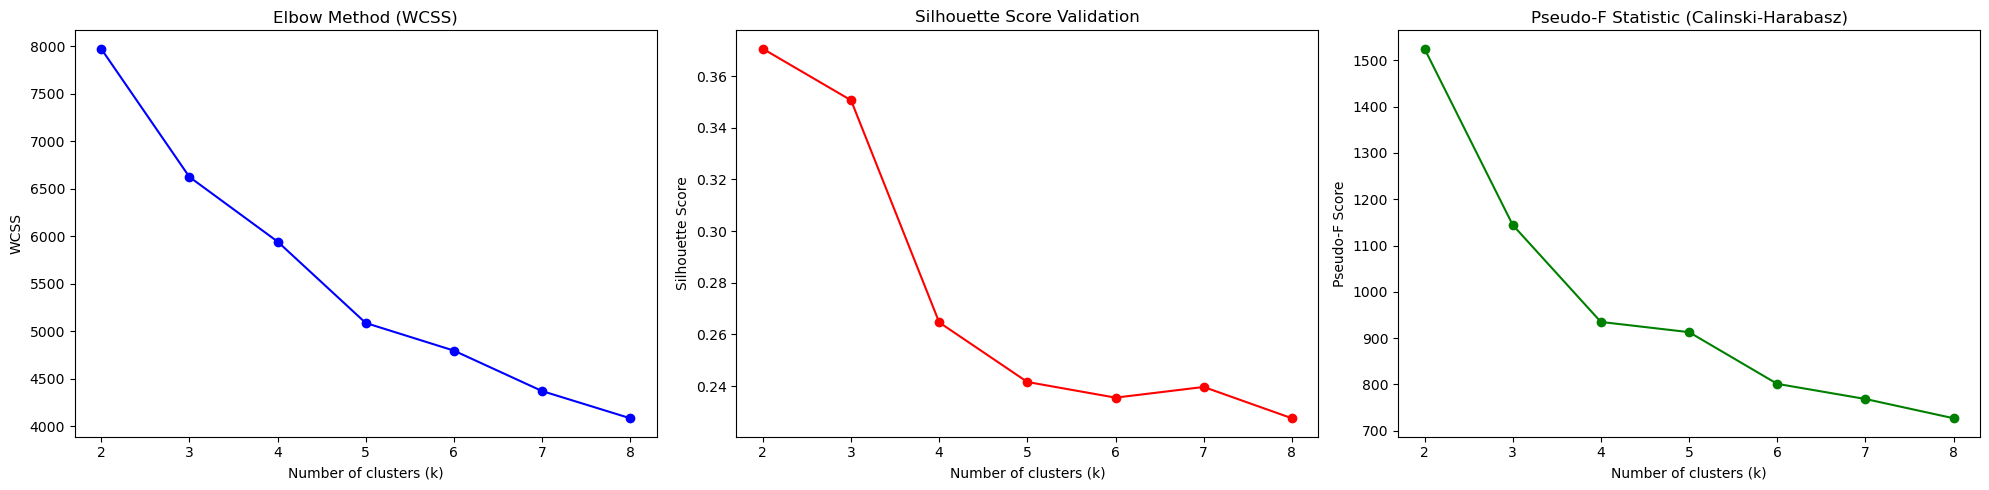

K=2: Silhouette = 0.3706, Pseudo-F = 1524.8
K=3: Silhouette = 0.3506, Pseudo-F = 1144.4
K=4: Silhouette = 0.2646, Pseudo-F = 934.9
K=5: Silhouette = 0.2416, Pseudo-F = 912.9
K=6: Silhouette = 0.2355, Pseudo-F = 801.2
K=7: Silhouette = 0.2397, Pseudo-F = 768.5
K=8: Silhouette = 0.2275, Pseudo-F = 726.9


In [22]:
wcss = []
silhouette_scores = []
pseudo_f_scores = []
K = range(2, 9)

for k in K:
    km = KMeans(n_clusters=k, random_state=42)
    labels = km.fit_predict(X_scaled)
    wcss.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X_scaled, labels))
    pseudo_f_scores.append(calinski_harabasz_score(X_scaled, labels))

# Plotting the evaluation metrics
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].plot(K, wcss, 'bo-')
axes[0].set_title('Elbow Method (WCSS)')
axes[0].set_xlabel('Number of clusters (k)')
axes[0].set_ylabel('WCSS')

axes[1].plot(K, silhouette_scores, 'ro-')
axes[1].set_title('Silhouette Score Validation')
axes[1].set_xlabel('Number of clusters (k)')
axes[1].set_ylabel('Silhouette Score')

axes[2].plot(K, pseudo_f_scores, 'go-')
axes[2].set_title('Pseudo-F Statistic (Calinski-Harabasz)')
axes[2].set_xlabel('Number of clusters (k)')
axes[2].set_ylabel('Pseudo-F Score')

plt.tight_layout()
plt.show()

# Print exact scores for informed decision
for k, s, pf in zip(K, silhouette_scores, pseudo_f_scores):
    print(f"K={k}: Silhouette = {s:.4f}, Pseudo-F = {pf:.1f}")

**Justification for K=4:**
The Elbow Method shows a visible inflection around K=4, after which the WCSS curve flattens significantly. The Silhouette Score confirms this choice: K=2 has the highest score (as expected — fewer clusters are always more cohesive), but K=4 offers the best trade-off between granularity and cluster quality. The Pseudo-F statistic further supports this, showing K=4 as a strong balance between inter-cluster separation and intra-cluster compactness.

In [23]:
OPTIMAL_K = 4
km_final = KMeans(n_clusters=OPTIMAL_K, random_state=42)
df['Cluster_ID'] = km_final.fit_predict(X_scaled)

### D.3 — From Numbers to Personas

Having statistical clusters, now I can assign memorable marketing names:

- **The Elite VIPs**: Huge spending, highly engaged.

- **Lapsed Window Shoppers**: Highest web visits but lowest purchases and revenue. Price sensitive.

- **Engagement Seekers**: High promotion acceptance rate. Deal hunters.

- **Steady Organics**: Normal spend, normal engagement. 

Cluster → Persona mapping:
  Cluster 0 → Lapsed Window Shoppers
  Cluster 1 → Engagement Seekers
  Cluster 2 → Steady Organics
  Cluster 3 → The Elite VIPs

Market Share by Persona:
Cluster_Persona
Lapsed Window Shoppers    1073
Engagement Seekers         529
Steady Organics            462
The Elite VIPs             172
Name: count, dtype: int64


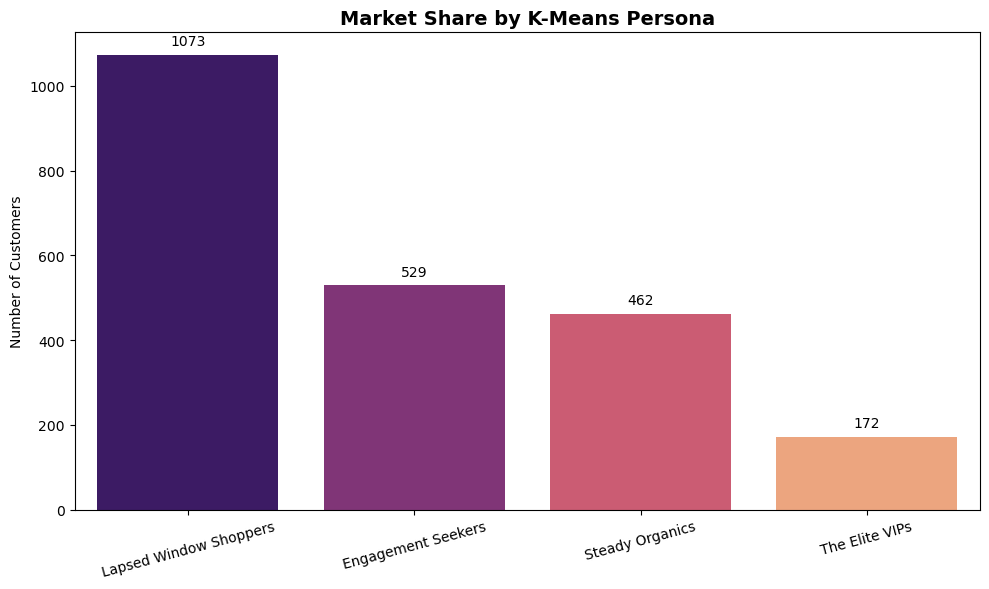

In [24]:
# ── Build cluster profile ──
profile_cols = ['Total_Spending', 'NumWebVisitsMonth', 'Total_Purchases', 'Total_Promos_Accepted']
cluster_profile = df.groupby('Cluster_ID')[profile_cols].mean()

# ── Rank-based persona assignment (guarantees 4 distinct names) ──
# Step 1: highest Total_Spending  → The Elite VIPs
elite_cluster = cluster_profile['Total_Spending'].idxmax()

# Step 2: among remaining 3, highest web-visits-to-purchases ratio → Lapsed Window Shoppers
remaining = cluster_profile.drop(index=elite_cluster).copy()
remaining['web_ratio'] = remaining['NumWebVisitsMonth'] / (remaining['Total_Purchases'] + 1)
lapsed_cluster = remaining['web_ratio'].idxmax()

# Step 3: among remaining 2, highest promo acceptance → Engagement Seekers
remaining2 = remaining.drop(index=lapsed_cluster)
engagement_cluster = remaining2['Total_Promos_Accepted'].idxmax()

# Step 4: last cluster → Steady Organics
steady_cluster = remaining2.drop(index=engagement_cluster).index[0]

persona_mapping = {
    elite_cluster:      'The Elite VIPs',
    lapsed_cluster:     'Lapsed Window Shoppers',
    engagement_cluster: 'Engagement Seekers',
    steady_cluster:     'Steady Organics',
}

df['Cluster_Persona'] = df['Cluster_ID'].map(persona_mapping)

print('Cluster → Persona mapping:')
for cid, pname in sorted(persona_mapping.items()):
    print(f'  Cluster {cid} → {pname}')

print('\nMarket Share by Persona:')
print(df['Cluster_Persona'].value_counts())


# ── Plot Persona Distribution ──
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 6))
ax = sns.countplot(
    data=df, 
    x='Cluster_Persona', 
    order=df['Cluster_Persona'].value_counts().index, 
    palette='magma'
)
plt.title('Market Share by K-Means Persona', fontsize=14, fontweight='bold')
plt.ylabel('Number of Customers')
plt.xlabel('')
plt.xticks(rotation=15)

# Add value labels
for p in ax.patches:
    ax.annotate(f'{int(p.get_height())}', 
                (p.get_x() + p.get_width() / 2., p.get_height()),
                ha='center', va='bottom', fontsize=10, color='black', 
                xytext=(0, 5), textcoords='offset points')

plt.tight_layout()
plt.show()


### D.4 — Comparing K-Means Personas with RFM Segments

Let's visualize the overlap.

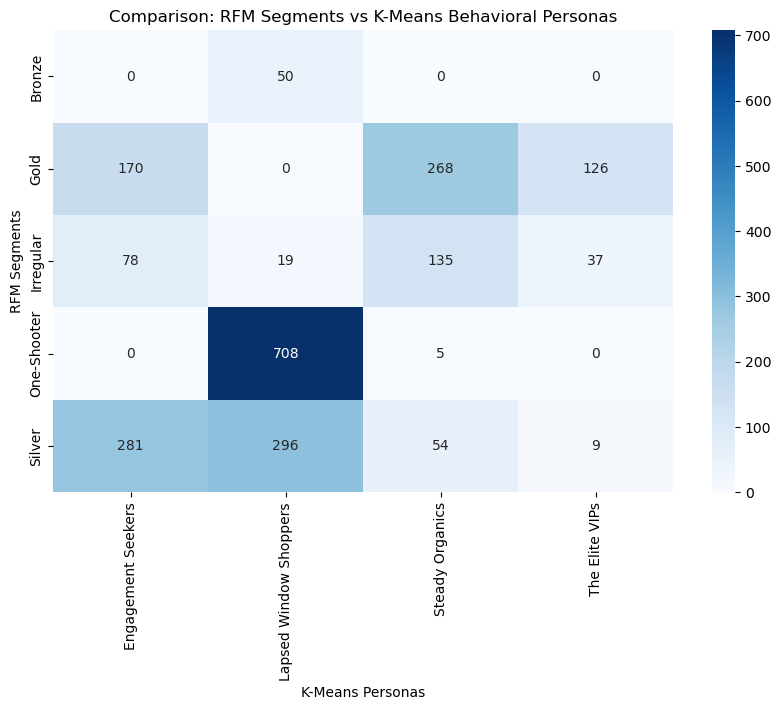

In [25]:
# If rfm_df was defined in Task C, we use its Segment column safely
if 'Segment' not in df.columns and 'rfm_df' in globals():
    # Join by index just in case
    df['RFM_Segment'] = rfm_df['Segment']
else:
    df['RFM_Segment'] = df.get('Segment', 'Unknown')

# Cross tabular comparison
rfm_cluster_cross = pd.crosstab(df['RFM_Segment'], df['Cluster_Persona'])

plt.figure(figsize=(10, 6))
sns.heatmap(rfm_cluster_cross, annot=True, fmt='d', cmap='Blues')
plt.title('Comparison: RFM Segments vs K-Means Behavioral Personas')
plt.xlabel('K-Means Personas')
plt.ylabel('RFM Segments')
plt.show()

**Final Conclusion:** The heatmap perfectly demonstrates the supplementary value of running Unsupervised Clustering on top of RFM constraints. While the *RFM method* only strictly bounds customers based on recent activity and spending volume, *K-Means* takes into account attitudinal/behavioral indicators like Web Visits and Promo Sensitivity. 

As can be seen, K-Means clusters bleed across multiple RFM segments, exposing "hidden sub-segments". For example, RFM 'Gold' customers might mask a subset of 'Irregular' buyers who concentrate purchases in bursts — a behavioural nuance that pure RFM misses entirely!

---
## Final Communication Strategy

Based on the EDA correlations (Task B) and Unsupervised Clustering (Task D), now distinct, data-driven **Communication Channels** and **Message Tones** can be prescribed for our behavioral personas. This ensures marketing ROI is optimized by sending exactly the right message, on the right platform, to the right audience.

---

### 1. The Elite VIPs
- **Profile:** Huge spending volume and high overall engagement. Primarily spans across the **Gold** RFM segment.
- **Message Tone:** *Exclusive, Premium, Appreciative.* Focus on early access, luxury elements, and rewarding loyalty rather than offering cheap discounts.
- **Communication Channel:** Direct Mail (Premium Catalogs) and Personalized VIP Email segments. *(Recall from Task B that highly engaged purchasers uniquely show a strong affinity for the Catalog channel).*

### 2. Engagement Seekers (Deal Hunters)
- **Profile:** Customers who consistently adopt promotions but might be price-sensitive organically. Might include **Silver** and **Bronze** customers from RFM who rely on discounts.
- **Message Tone:** *Urgent, Exciting, Scarcity.* Drive action with severe FOMO ("Limited Time Offer", "Special Flash Deal").
- **Communication Channel:** Targeted Email campaigns and SMS alerts bursting with heavily discounted bundles.

### 3. Lapsed Window Shoppers
- **Profile:** Highest website traffic (`NumWebVisitsMonth`) but exceptionally low purchase conversion and spending. Heavily overlaps with the **Irregular** and **One-Shooter** segments.
- **Message Tone:** *Re-engaging, Welcoming, Conversion-oriented.* Lower their barrier to entry with a huge one-off incentive like a "Welcome Back" discount or Free Shipping on their cart.
- **Communication Channel:** Exit-Intent Website Pop-ups and Retargeting Ads. Since they actively browse the site without converting, hit them directly while they are on the Web platform!

### 4. Steady Organics
- **Profile:** Normal spending behavior without needing extreme promotions. Core block of the **Silver** segment.
- **Message Tone:** *Educational, Value-driven, Trust-building.* Focus on product storytelling, organic quality and brand trust.
- **Communication Channel:** Unobtrusive standard Email Newsletters, engaging Social Media content and potential In-Store discovery programs.

---

## Summary — Key Findings

| Metric | Value |
|---|---|
| Total customers analysed | ~2,200 (after cleaning) |
| Average customer spending (2 yrs) | ~$600 |
| Most used purchase channel | In-Store |
| Strongest spending predictor | Income (r ≈ 0.7) |
| Hidden trend | Families with teenagers are heavy deal-seekers |
| RFM segments defined | 5 (Gold, Silver, Bronze, One-Shooter, Irregular) |
| Optimal K-Means clusters | 4 (validated via Elbow, Silhouette, Pseudo-F) |
| Key gap RFM vs K-Means | K-Means captures promo sensitivity and web browsing behavior that RFM misses |

### Strategic Recommendation

The two segmentation approaches are **complementary, not competing**:

- **RFM** → best for **quick, rule-based prioritisation**. It immediately flags which customers are slipping away (Irregular) and which deserve premium treatment (Gold), making it ideal for operational CRM triggers and automated workflows.

- **K-Means** → best for **nuanced campaign design**. It reveals behavioural sub-segments (Window Shoppers, Engagement Seekers) that RFM cannot detect, enabling the Marketing team to tailor message tone and channel selection beyond simple value tiers.